In [ ]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import cross_val_score
from skopt import BayesSearchCV
from skopt.space import Integer, Real

x, y = make_classification(n_samples=1000, n_features=20, n_informative=10,
                           n_redundant=5, random_state=42)

rf = RandomForestClassifier(random_state=42)

search_space = {
    'n_estimators': Integer(50, 500),
    'max_depth': Integer(3, 20),
    'min_samples_split': Integer(2, 20),  # 修正这里
    'min_samples_leaf': Integer(1, 20),
    'max_features': Real(0.1, 1.0)
}

opt = BayesSearchCV(
    rf, 
    search_space,
    n_iter=30,
    cv = 3,
    scoring='accuracy',
    random_state=42
)

opt.fit(x, y)

print('Best hyperparameters:', opt.best_params_)
print('Best score:', opt.best_score_)

Best hyperparameters: OrderedDict([('max_depth', 20), ('max_features', 0.1), ('min_samples_leaf', 1), ('min_samples_split', 3), ('n_estimators', 500)])
Best score: 0.9360048671425917


Text(0, 0.5, 'Number of MSI images')

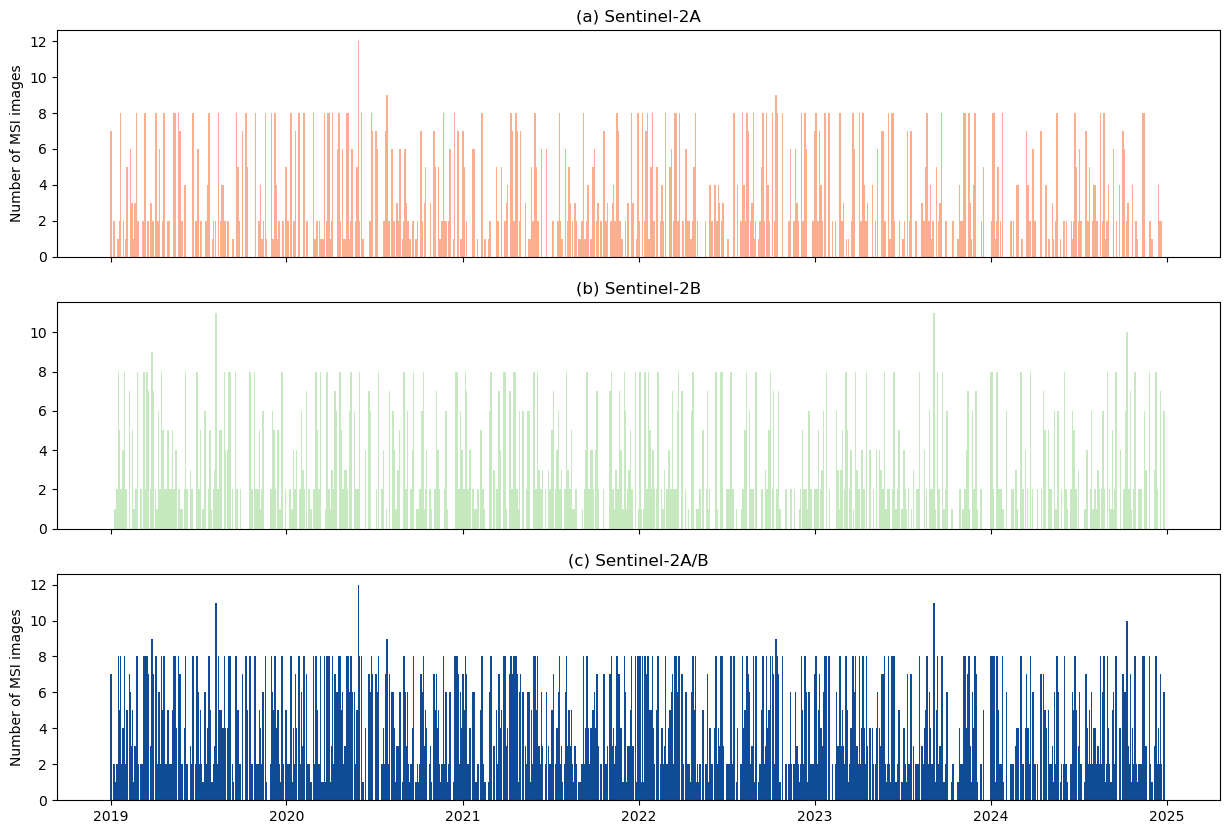

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import datetime as dt

# 假设你已准备好数据
z = 'E:/Downloads/tes/S2_daily_counts_UK_2019_2024c.csv'
df = pd.read_csv(z, parse_dates=["date"])

# 创建画布
fig, axs = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

# 设置颜色
colors = ['#fcae91', '#c7e9c0', "#104B98"]

# Sentinel-2A
axs[0].bar(df['date'], df['s2a_count'], color=colors[0], width=3)
# plt.axvline(pd.Timestamp("2018-01-01"), color='red', linestyle='--')
# plt.axhline(df['s2a_count'].mean(), color='red', linestyle='--')
#plt.text(pd.Timestamp("2016-07-01"), 600, f"Average: {df['s2a_count'].mean():.2f}, Std: {df['s2a_count'].std():.2f}")
axs[0].set_ylabel("Number of MSI images")
axs[0].set_title("(a) Sentinel-2A")

# # Sentinel-2B
axs[1].bar(df['date'], df['s2b_count'], color=colors[1], width=3)
# axs[1].axvline(pd.Timestamp("2017-06-29"), color='olive', linestyle='--')
# axs[1].axvline(pd.Timestamp("2018-01-01"), color='olive', linestyle='--')
# axs[1].axhline(df['s2b_count'].mean(), color='olive', linestyle='--')
#axs[1].text(pd.Timestamp("2016-07-01"), 600, f"Average: {df['s2b_count'].mean():.2f}, Std: {df['s2b_count'].std():.2f}")
axs[1].set_title("(b) Sentinel-2B")


# # Sentinel-2A/B
axs[2].bar(df['date'], df['total_count'], color=colors[2], width=3)
# axs[2].axvline(pd.Timestamp("2017-06-29"), color='blue', linestyle='--')
# axs[2].axhline(df['total_count'].mean(), color='blue', linestyle='--')
# axs[2].text(pd.Timestamp("2016-07-01"), 1000, f"Average: {df['total_count'].mean():.2f}, Std: {df['total_count'].std():.2f}")
axs[2].set_title("(c) Sentinel-2A/B")
axs[2].set_ylabel("Number of MSI images")

# # 设置横坐标时间格式
# axs[2].xaxis.set_major_locator(mdates.YearLocator())
# axs[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# plt.xlabel("Date")
# plt.tight_layout()
# plt.show()
# 

In [40]:
z = 'E:/Downloads/tes/S2_daily_counts_UK_2019_2024c.csv'
df = pd.read_csv(z, parse_dates=["date"])
df['year']

0       2019
1       2019
2       2019
3       2019
4       2019
        ... 
2186    2024
2187    2024
2188    2024
2189    2024
2190    2024
Name: year, Length: 2191, dtype: int64

In [2]:
z = 'E:/Downloads/tes/S2_Landsat_daily_counts_UK_2019_2024.csv'
df = pd.read_csv(z, parse_dates=["date"])
df.columns

Index(['system:index', 'date', 'Sentinel-2A', 'Sentinel-2B', 'Sentinel-2A/B',
       '.geo', 'year', 'Landsat 8', 'Landsat 9', 'ALL', 'Landsat 8/9'],
      dtype='object')

In [8]:
df['Sentinel-2A'].sum()

17692

In [261]:
import pandas as pd

# 假设你的 DataFrame 名字是 df
df['date'] = pd.to_datetime(df['date'])

# 新增一列 "month"，格式为 "YYYY-MM"
df['month'] = df['date'].dt.to_period('M')

# 按月汇总（对数值列求和）
monthly_stats = df.groupby('month')[[
    'Sentinel-2A',
    'Sentinel-2B',
    'Sentinel-2A/B',
    'Landsat 8',
    'Landsat 9',
    'ALL',
    'Landsat 8/9',

]].sum().reset_index()

a = df.groupby('month')[[
   'year',

]].mean().reset_index()


# 如果想要 month 显示为字符串而不是 period
monthly_stats['month'] = monthly_stats['month'].astype(str)

monthly_stats['time'] = pd.to_datetime(monthly_stats['month'])

monthly_stats['year'] = a['year'].astype(int)
monthly_stats

,month,Sentinel-2A,Sentinel-2B,Sentinel-2A/B,Landsat 8,Landsat 9,ALL,Landsat 8/9,time,year
0,2019-01,241,280,521,15,0,536,15,2019-01-01,2019
1,2019-02,229,197,426,34,0,460,34,2019-02-01,2019
2,2019-03,221,332,553,31,0,584,31,2019-03-01,2019
3,2019-04,205,271,476,44,0,520,44,2019-04-01,2019
4,2019-05,306,263,569,38,0,607,38,2019-05-01,2019
...,...,...,...,...,...,...,...,...,...,...
67,2024-08,274,324,598,33,36,667,69,2024-08-01,2024
68,2024-09,241,221,462,48,30,540,78,2024-09-01,2024
69,2024-10,256,258,514,32,44,590,76,2024-10-01,2024
70,2024-11,201,136,337,16,16,369,32,2024-11-01,2024


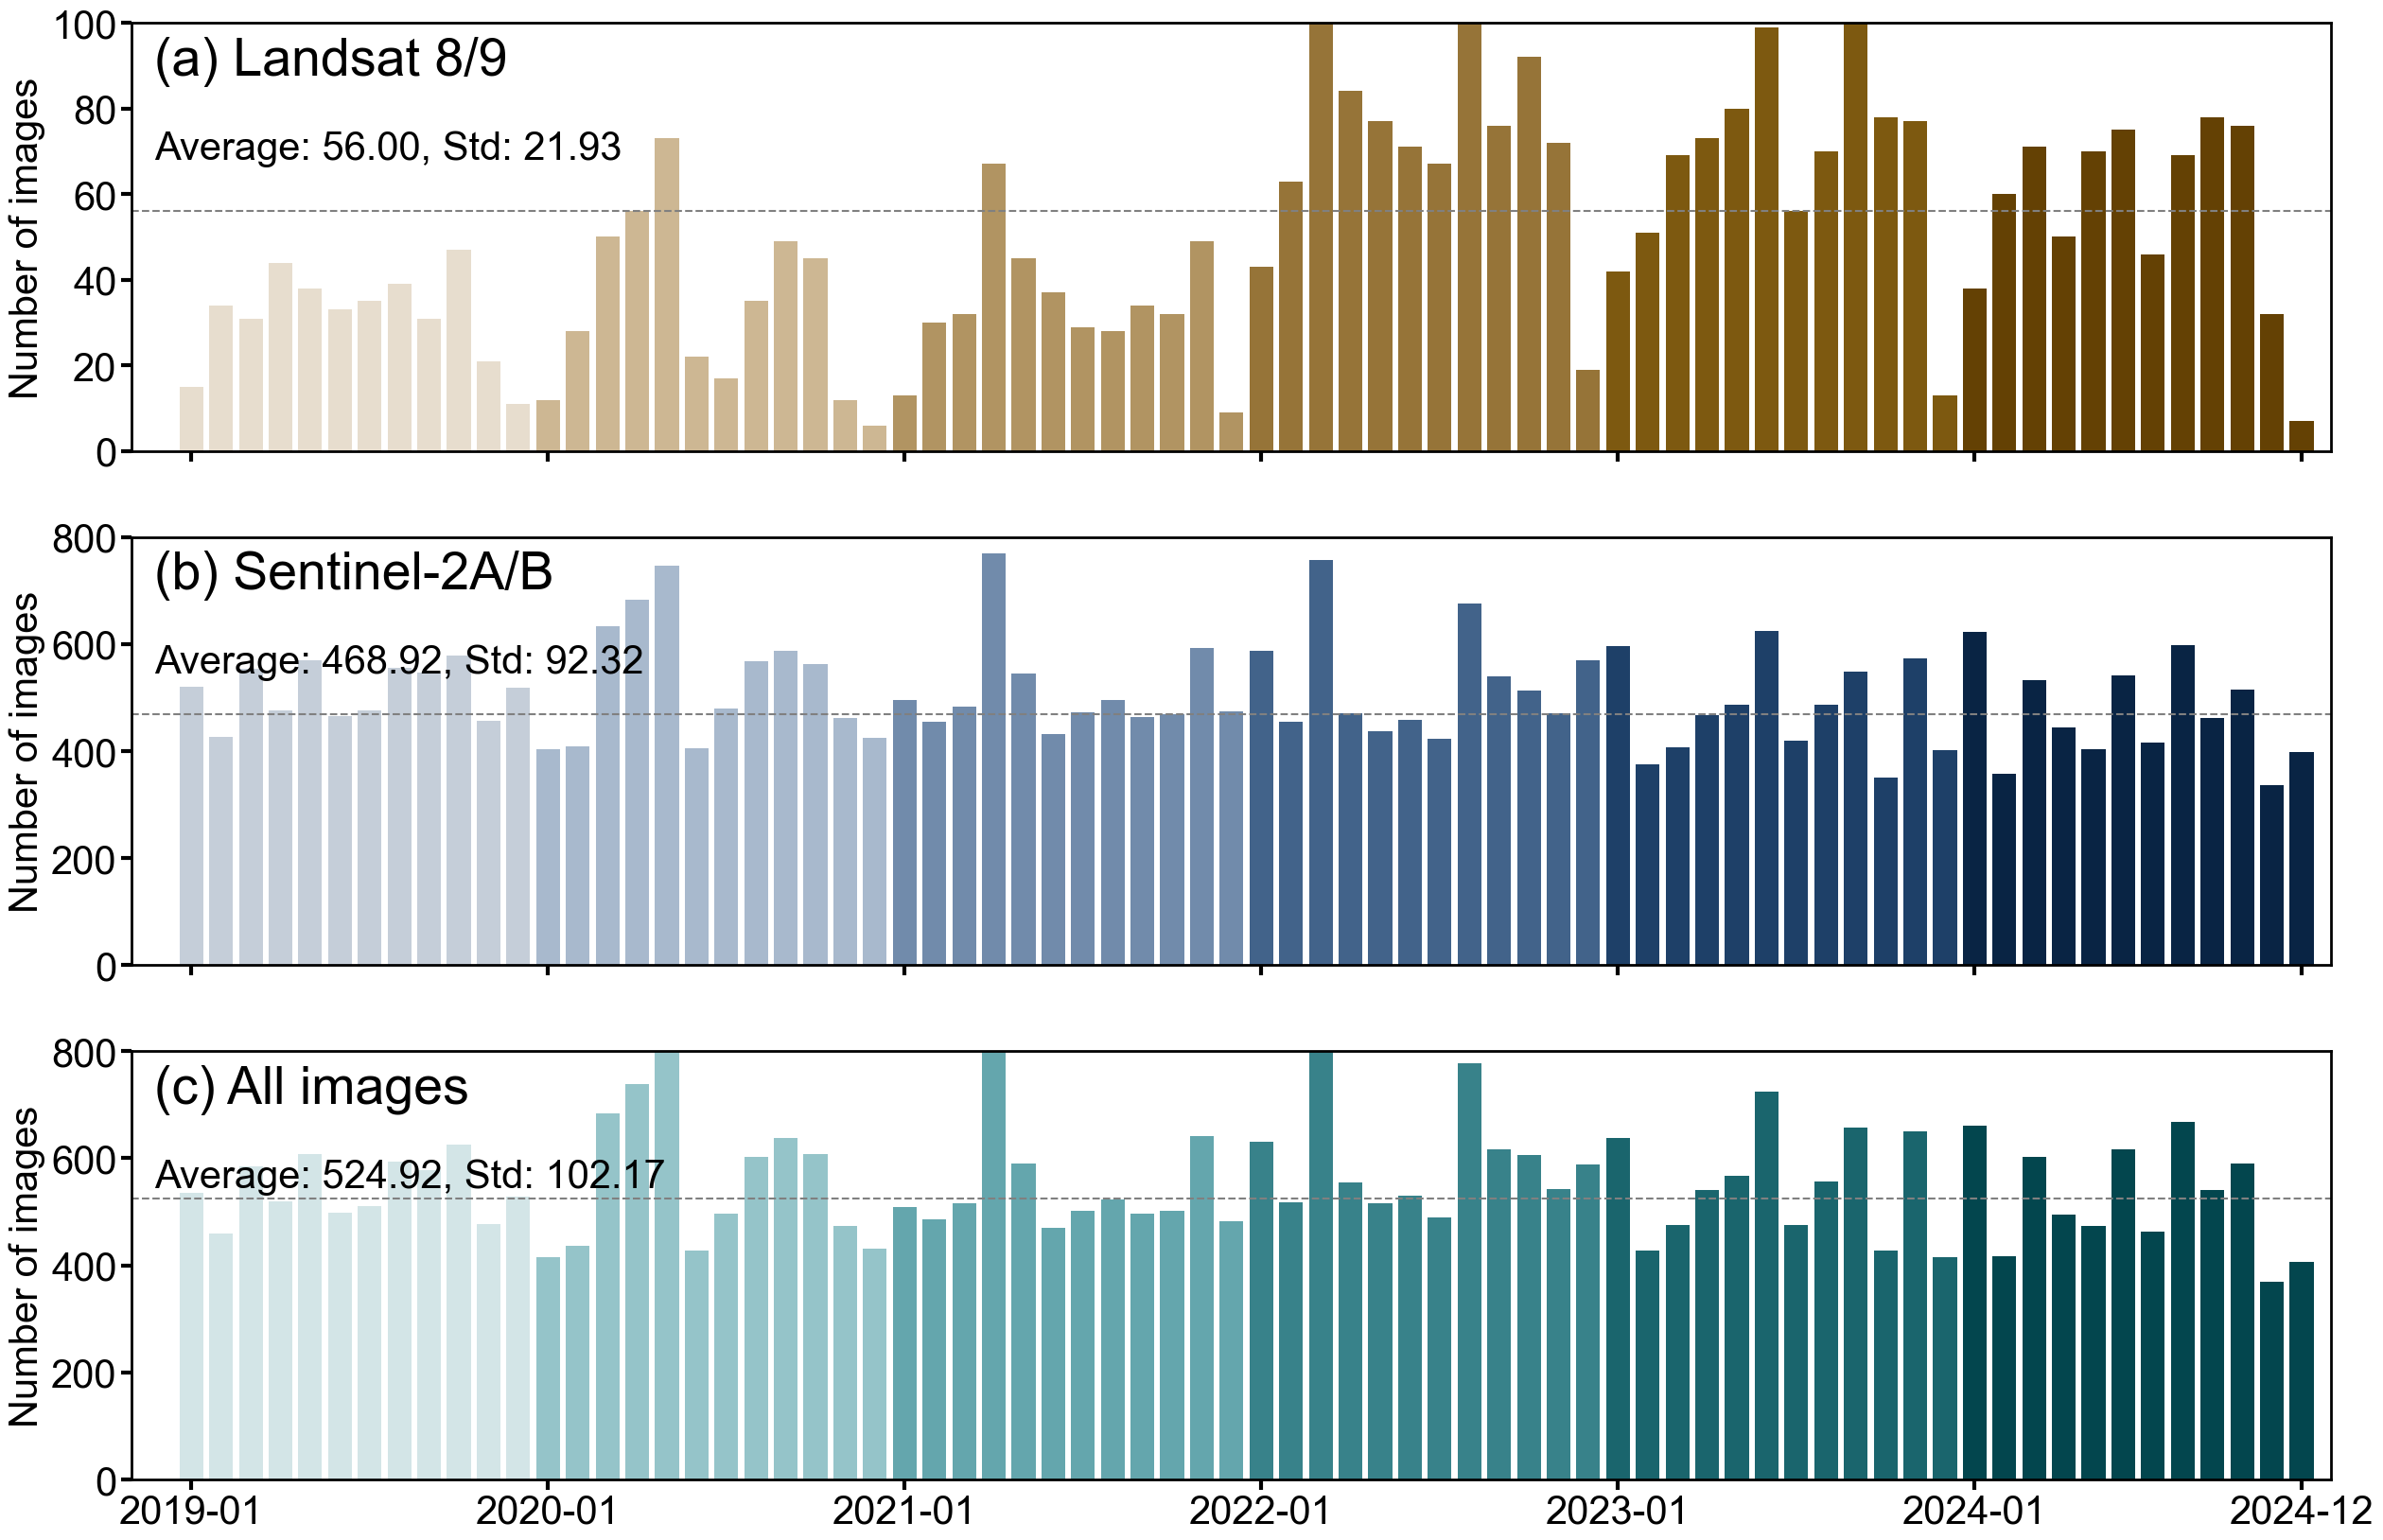

In [344]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap
import numpy as np
from datetime import timedelta
from matplotlib.patches import Patch

plt.rcParams['font.family'] = 'Arial'

fig, axs = plt.subplots(3, 1, figsize=(30, 20), sharex=True)
titles = ['(a) Landsat 8/9', '(b) Sentinel-2A/B', '(c) All images']
cols = ['Landsat 8/9', 'Sentinel-2A/B', 'ALL']
colors_per_year = {
    2019: "#C5CED9",  # light pink
    2020: "#A8B9CD",  # medium pink
    2021: "#718BAB",  # dark pink
    2022: "#42638A",  # darkest
    2023: "#1E4068",  # green
    2024: "#092444",  # darker green
}
# colors_per_year = {
#     2019: "#78AFE9", # light pink
#     2020: "#1B549B",  # medium pink
#     2021: "#78AFE9",  # dark pink
#     2022: "#1B549B",  # darkest
#     2023: "#78AFE9",  # green
#     2024: "#1B549B",  # darker green
# }

colors_per_year2 = {
    2019: "#D3E5E7",  # light pink
    2020: "#95C4C9",  # medium pink
    2021: "#64A6AD",  # dark pink
    2022: "#38828A",  # darkest
    2023: "#1A656D",  # green
    2024: "#03464E",  # darker green
}
# colors_per_year2 = {
#     2019: "#8CD8E0",  # light pink
#     2020: "#1A656D",  # medium pink
#     2021: "#8CD8E0",  # dark pink
#     2022: "#1A656D",  # darkest
#     2023: "#8CD8E0",  # green
#     2024: "#1A656D",  # darker green
# }

colors_per_year3 = {
    2019: "#E7DDCE",  # light pink
    2020: "#CDB793",  # medium pink
    2021: "#B19462",  # dark pink
    2022: "#967438",  # darkest
    2023: "#7D5910",  # green
    2024: "#644104",  # darker green
}
# colors_per_year3 = {
#     2019: "#F5D7A9",  # light pink
#     2020: "#90691A",  # medium pink
#     2021: "#F5D7A9", # dark pink
#     2022: "#90691A",  # darkest
#     2023: "#F5D7A9",  # green
#     2024: "#90691A",   # darker green
# }


list_colors_per_year = [colors_per_year3, colors_per_year, colors_per_year2]

# 给每个月生成一个整数索引
monthly_stats["month_idx"] = range(len(monthly_stats))

ylim_range_list = [[0, 100, 20],[0, 800, 200], [0, 800, 200]]

for i, ax in enumerate(axs):
    for year, color in list_colors_per_year[i].items():
        df_year = monthly_stats[monthly_stats['year'] == year]
        ax.bar(df_year["month_idx"], df_year[cols[i]], color=color)


    avg = df_year[cols[i]].mean()
    std = df_year[cols[i]].std()
    ax.axhline(avg, linestyle='--', color='gray')

    # 替代 set_title，在左上角添加文本+边框
    ax.text(
        0.01, 0.97,
        f"{titles[i]}", #\nAverage: {avg:.2f}, Std: {std:.2f}
        transform=ax.transAxes,
        verticalalignment='top',
        horizontalalignment='left',
        fontsize=40,
        #bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', boxstyle='round,pad=0.3')
    )
    ax.text(
        0.01, 0.75,   # ✅ 调低 y 值 (0.98 → 0.90)
        f"Average: {avg:.2f}, Std: {std:.2f}",
        transform=ax.transAxes,
        verticalalignment='top',
        horizontalalignment='left',
        fontsize=30,
        # bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', boxstyle='round,pad=0.3')
    )

    # ✅ 每隔12个刻度（即每年）显示一次
    xticks = list(monthly_stats["month_idx"][::12])  # 每隔12个月
    xticklabels = list(monthly_stats["month"][::12])
    if xticks[-1] != monthly_stats['month_idx'].iloc[-1]:
       xticks.append(monthly_stats['month_idx'].iloc[-1])
       xticklabels.append(monthly_stats['month'].iloc[-1])
    ax.set_xticks(xticks)
    
    ax.set_xticklabels(xticklabels, fontsize=30)
    ax.set_xlim(-2, len(monthly_stats))
    
    ax.set_ylim(ylim_range_list[i][0], ylim_range_list[i][1])
    yticks = np.arange(-ylim_range_list[i][0], ylim_range_list[i][1] + ylim_range_list[i][2], ylim_range_list[i][2])
    ax.set_yticks(yticks)
    
    ax.tick_params(axis='y', labelsize=30)
    ax.set_ylabel("Number of images", fontsize=30)

    for spine in ax.spines.values():
        spine.set_linewidth(2) 
        
    ax.tick_params(axis='both', which='major', width=3, length=8)   # 主刻度
    ax.tick_params(axis='both', which='minor', width=2, length=5)   # 次刻度（如果有）

In [283]:
xticks = list(monthly_stats["month_idx"][::12])  # 每隔12个月
if xticks[-1] != monthly_stats["month_idx"].iloc[-1]:
    xticks.append(monthly_stats["month_idx"].iloc[-1])  # 加上最后一个
xticks

[0, 12, 24, 36, 48, 60, 71]

In [267]:
monthly_stats

,month,Sentinel-2A,Sentinel-2B,Sentinel-2A/B,Landsat 8,Landsat 9,ALL,Landsat 8/9,time,year,month_idx
0,2019-01,241,280,521,15,0,536,15,2019-01-01,2019,0
1,2019-02,229,197,426,34,0,460,34,2019-02-01,2019,1
2,2019-03,221,332,553,31,0,584,31,2019-03-01,2019,2
3,2019-04,205,271,476,44,0,520,44,2019-04-01,2019,3
4,2019-05,306,263,569,38,0,607,38,2019-05-01,2019,4
...,...,...,...,...,...,...,...,...,...,...,...
67,2024-08,274,324,598,33,36,667,69,2024-08-01,2024,67
68,2024-09,241,221,462,48,30,540,78,2024-09-01,2024,68
69,2024-10,256,258,514,32,44,590,76,2024-10-01,2024,69
70,2024-11,201,136,337,16,16,369,32,2024-11-01,2024,70


In [ ]:
df_year['time'].min() 

True

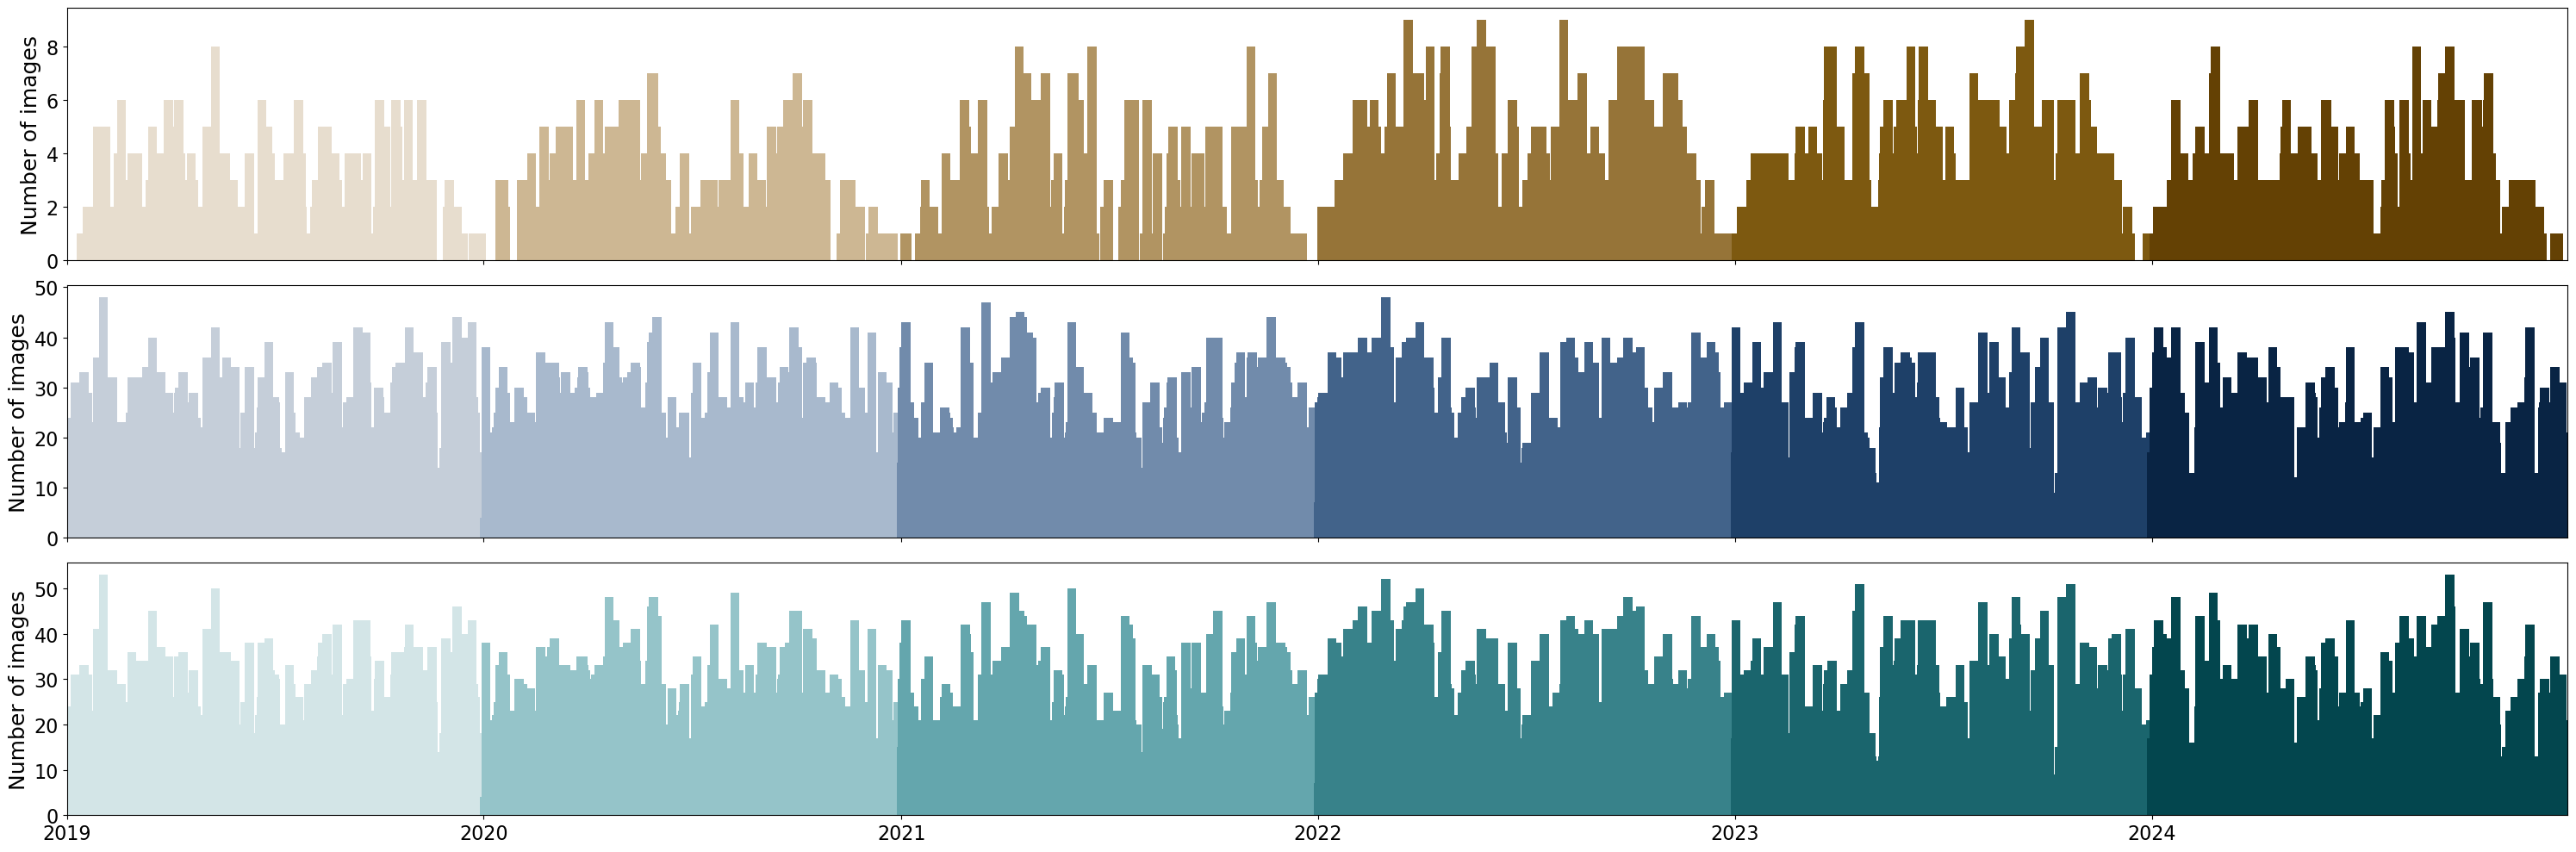

In [184]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap
import numpy as np
from datetime import timedelta
from matplotlib.patches import Patch
# 1. 读取数据
z = 'E:/Downloads/tes/S2_daily_counts_UK_2019_2024_a.csv'
z = 'E:/Downloads/tes/S2_Landsat_daily_counts_UK_2019_2024.csv'
df = pd.read_csv(z, parse_dates=["date"])

# 2. 准备绘图
fig, axs = plt.subplots(3, 1, figsize=(30, 10), sharex=True)
titles = ['(b) Landsat 8/9', '(c) Sentinel-2A/B', '(d) All images']
cols = ['Landsat 8/9', 'Sentinel-2A/B', 'ALL']
colors_per_year = {
    2019: "#C5CED9",  # light pink
    2020: "#A8B9CD",  # medium pink
    2021: "#718BAB",  # dark pink
    2022: "#42638A",  # darkest
    2023: "#1E4068",  # green
    2024: "#092444",  # darker green
}

colors_per_year2 = {
    2019: "#D3E5E7",  # light pink
    2020: "#95C4C9",  # medium pink
    2021: "#64A6AD",  # dark pink
    2022: "#38828A",  # darkest
    2023: "#1A656D",  # green
    2024: "#03464E",  # darker green
}

colors_per_year3 = {
    2019: "#E7DDCE",  # light pink
    2020: "#CDB793",  # medium pink
    2021: "#B19462",  # dark pink
    2022: "#967438",  # darkest
    2023: "#7D5910",  # green
    2024: "#644104",  # darker green
}
list_colors_per_year = [colors_per_year3, colors_per_year, colors_per_year2]

# 3. 绘制每个子图
for i, ax in enumerate(axs):
    for year, color in list_colors_per_year[i].items():
        df_year = df[df['year'] == year]
        ax.bar(df_year["date"], df_year[cols[i]], color=color, width=8)

    # 添加平均线
    # avg = df[cols[i]].mean()
    # std = df[cols[i]].std()
    # ax.axhline(avg, linestyle='--', color='gray')

    # # 替代 set_title，在左上角添加文本+边框
    # ax.text(
    #     0.01, 0.98,
    #     f"{titles[i]}\nAverage: {avg:.2f}, Std: {std:.2f}", #\nAverage: {avg:.2f}, Std: {std:.2f}
    #     transform=ax.transAxes,
    #     verticalalignment='top',
    #     horizontalalignment='left',
    #     fontsize=20,
    #     #bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', boxstyle='round,pad=0.3')
    # )

    #Y 轴标签字体加大
    ax.set_ylabel("Number of images", fontsize=18)
    ax.set_xlim(df['date'].min() , df['date'].max())
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=16)


#plt.subplots_adjust(left=0.5, right=0.98)

# 时间轴设置
# axs[-1].xaxis.set_major_locator(mdates.YearLocator())
# axs[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
# plt.xlabel("Date", fontsize=14)
plt.tight_layout()
plt.show()



In [198]:
df['date'].max()

Timestamp('2024-12-30 00:00:00')

In [182]:
print(df['date'].min())

2019-01-01 00:00:00


In [183]:
df['date'].min() - timedelta(days=30)

Timestamp('2018-12-02 00:00:00')

In [1]:
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.crs import CRS

# 输入和输出文件路径
input_path = r"G:\Tide_flat_and_elevation_mapping\tidal_range\tidal_range.tif"
output_path = r"G:\Tide_flat_and_elevation_mapping\tidal_range\Tida_range_out.tif"

# 定义目标CRS。同样，这里以'EPSG:3832'为例。
dst_crs = CRS.from_epsg(3832) # 请根据你的实际需求确认此CRS是否合适

with rasterio.open(input_path) as src:
    # 计算目标坐标系的变换参数、宽度和高度
    dst_transform, dst_width, dst_height = calculate_default_transform(
        src.crs, dst_crs, src.width, src.height, *src.bounds)
    
    # 更新输出文件的元数据（profile）
    dst_profile = src.profile
    dst_profile.update({
        'crs': dst_crs,
        'transform': dst_transform,
        'width': dst_width,
        'height': dst_height
    })
    
    # 创建输出文件并执行重投影
    with rasterio.open(output_path, 'w', **dst_profile) as dst:
        for i in range(1, src.count + 1):
            reproject(
                source=rasterio.band(src, i),
                destination=rasterio.band(dst, i),
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=dst_transform,
                dst_crs=dst_crs,
                resampling=Resampling.nearest # 可选择其他重采样方法，如bilinear, cubic等:cite[2]:cite[3]
            )

In [3]:
# 使用rasterio重投影到太平洋中心投影的示例
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling

input_path = r"G:\Tide_flat_and_elevation_mapping\tidal_range\tidal_range.tif"
output_path = r"G:\Tide_flat_and_elevation_mapping\tidal_range\Tida_range_out2.tif"

with rasterio.open(input_path) as src:
    # 定义目标CRS：太平洋中心世界墨卡托
    dst_crs = 'EPSG:3832'
    
    # 计算变换参数
    transform, width, height = calculate_default_transform(
        src.crs, dst_crs, src.width, src.height, *src.bounds
    )
    
    # 更新元数据并写入新文件
    profile = src.profile.copy()
    profile.update({
        'crs': dst_crs,
        'transform': transform,
        'width': width,
        'height': height
    })
    
    with rasterio.open(output_path, 'w', **profile) as dst:
        for i in range(1, src.count + 1):
            reproject(
                source=rasterio.band(src, i),
                destination=rasterio.band(dst, i),
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=dst_crs,
                resampling=Resampling.bilinear
            )

In [4]:
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling

src_fp = r"G:\Tide_flat_and_elevation_mapping\tidal_range\tidal_range.tif"
dst_fp = r"G:\Tide_flat_and_elevation_mapping\tidal_range\Tida_range_out3.tif"

# input_path = r"G:\Tide_flat_and_elevation_mapping\tidal_range\tidal_range.tif"
# output_path = r"G:\Tide_flat_and_elevation_mapping\tidal_range\Tida_range_out2.tif"
# 定义以 lon_0=180 为中心的经纬 CRS（这样经度中心在 180）
dst_crs = '+proj=longlat +datum=WGS84 +lon_0=180 +no_defs'

with rasterio.open(src_fp) as src:
    transform, width, height = calculate_default_transform(
        src.crs, dst_crs, src.width, src.height, *src.bounds)
    kwargs = src.meta.copy()
    kwargs.update({
        'crs': dst_crs,
        'transform': transform,
        'width': width,
        'height': height
    })

    with rasterio.open(dst_fp, 'w', **kwargs) as dst:
        for i in range(1, src.count + 1):
            reproject(
                source=rasterio.band(src, i),
                destination=rasterio.band(dst, i),
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=dst_crs,
                resampling=Resampling.nearest)


In [6]:
import rasterio
from rasterio.transform import Affine

src_fp = r"G:\Tide_flat_and_elevation_mapping\tidal_range\tidal_range.tif"
dst_fp = r"G:\Tide_flat_and_elevation_mapping\tidal_range\Tida_range_out5.tif"

# src_fp = r"G:\Tide_flat_and_elevation_mapping\tidal_range\tidal_range.tif"
# dst_fp = r"G:\Tide_flat_and_elevation_mapping\tidal_range\Tida_range_out3.tif"

with rasterio.open(src_fp) as src:
    meta = src.meta.copy()
    transform = src.transform

    # 如果数据在 [180, 360)，则平移回 [-180, 180)
    if src.bounds.left > 180:
        # 修改仿射矩阵的 x 偏移量（col=0 的经度减去 360）
        transform = Affine(transform.a, transform.b, transform.c - 360,
                           transform.d, transform.e, transform.f)

    meta.update(transform=transform)

    with rasterio.open(dst_fp, "w", **meta) as dst:
        dst.write(src.read())

